# Optimización de hiperparámetros de ResNet50

Clasificación de defectos superficiales en palta Hass: PICADURA y RUSSET.

Se analiza el efecto de la tasa de aprendizaje y del dropout sobre el Macro-F1 durante el ajuste fino de ResNet50. Los ensayos mantienen las mismas imágenes, la arquitectura y el punto de partida del entrenamiento D1.

Se utiliza una búsqueda aleatoria con Optuna. El primer ensayo reproduce la configuración de referencia (learning rate de 1e-5 y dropout de 0.35) y se dispone de un presupuesto inicial de ocho ensayos. Cada ejecución inicia con los pesos de ImageNet y la cabeza D1, y utiliza un optimizador independiente.

El checkpoint se selecciona por la menor pérdida de validación (val_loss). Las configuraciones se ordenan posteriormente por Macro-F1 sobre VALIDATION. Se emplea early stopping con paciencia de cuatro épocas. No se aplica pruning porque el valor objetivo se calcula después de recuperar el checkpoint seleccionado.

TRAIN se utiliza para entrenar y VALIDATION para seleccionar configuraciones. No se utilizan predicciones de TEST. Se conservan las tres franjas de cámara y las transformaciones fotométricas del entrenamiento original.

La ejecución requiere el kernel `palta_gpu (CUDA)` en VS Code con WSL2. La búsqueda está desactivada inicialmente y los archivos de experimentos previos no se sobrescriben.

## 1. Configuración experimental

Se utiliza ResNet50 con pesos ImageNet, imágenes de 256 × 512 píxeles y tres franjas de cámara. Se mantienen una copia adicional de RUSSET, los pesos por clase, los aumentos fotométricos de entrenamiento de ±5 %, el lote de tamaño 1 y el ajuste fino del bloque `conv5`. Las capas BatchNormalization permanecen congeladas.

Solo se modifican la tasa de aprendizaje y el dropout. El presupuesto de ocho ensayos es una exploración inicial y no constituye una búsqueda exhaustiva. No se informan medidas de dispersión entre semillas si no se realizan repeticiones independientes.

In [1]:
from pathlib import Path, PureWindowsPath
import gc
import hashlib
import importlib.metadata
import json
import os
import platform
import random
import sys
import time
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "README.md").is_file() and (p / "utilidades_imagenes.py").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra este notebook desde la carpeta raiz en VS Code / WSL2.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from utilidades_imagenes import (
    encontrar_raiz, resolver_dataset, listar_imagenes,
    crear_dataset_tf, cargar_rgb, ajustar_tamano,
)

RAIZ = encontrar_raiz()
DATASET = resolver_dataset(RAIZ, "../DATASET_PALTA")
SEMILLA = 42
TAMANO = (256, 512)
CLASES = ["PICADURA", "RUSSET"]
BRILLO_EXTRA = (0.95, 1.05)
CONTRASTE_EXTRA = (0.95, 1.05)
RUN_ORIGEN = "D1_s42_03"
RUN_REFERENCIA = "FT_D1_PHOTO_s42_01"
SALIDA_ORIGEN = RAIZ / "7. resultados" / "entrenamiento"
SALIDA_HPO = RAIZ / "7. resultados" / "optimizacion_hiperparametros"
NOTEBOOK_ORIGEN = RAIZ / "6. entrenamiento" / "02_Experimento_Aumentos_Fotometricos.ipynb"

# Presupuesto piloto. Cambiar estos valores implica una nueva version del protocolo.
N_TRIALS_OBJETIVO = 8
EPOCAS_MAXIMAS = 8
LOTE = 1
LR_RANGO = (3e-6, 3e-5)
DROPOUT_RANGO = (0.25, 0.45)

os.environ.setdefault("KERAS_HOME", str(RAIZ / ".cache" / "keras"))
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise RuntimeError("No se detecta GPU. Seleccione el kernel palta_gpu (CUDA) en WSL2.")
try:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
except RuntimeError:
    pass  # La GPU puede estar inicializada en este kernel.
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    pass

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__, "| Optuna:", optuna.__version__)
print("GPU:", [g.name for g in gpus])
print("Carpeta raiz:", RAIZ)
print("Dataset encontrado:", DATASET.is_dir())
print("Punto de partida:", RUN_ORIGEN, "| Referencia historica:", RUN_REFERENCIA)
print("No se ha iniciado ningun entrenamiento.")


/home/tci_auto/.venvs/palta_gpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1793947918.315036   92000 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793947918.360375   92000 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793947919.841263   92000 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-

Python: /home/tci_auto/.venvs/palta_gpu/bin/python
TensorFlow: 2.21.0 | Optuna: 5.0.0
GPU: ['/physical_device:GPU:0']
Carpeta raiz: /mnt/c/Users/TCI_AUTO/Documents/Maestría UNI/4_2. Proyecto de Invetigación  2/PROYECTO_TI_2
Dataset encontrado: True
Punto de partida: D1_s42_03 | Referencia historica: FT_D1_PHOTO_s42_01
No se ha iniciado ningun entrenamiento.


## 2. Preparación de los datos

Se reutilizan las funciones de auditoría, exclusión de duplicados, generación de copias de RUSSET y aplicación de cambios fotométricos en TRAIN. Los archivos TIFF originales no se modifican.

In [3]:
# Funciones reproducidas del protocolo auditado de FT_D1_PHOTO.
# Se mantienen constantes en todos los ensayos.

def hash_archivo(ruta):
    calculo = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            calculo.update(bloque)
    return calculo.hexdigest()


def firma_tabla(tabla):
    texto = "\n".join(tabla["archivo"] + ":" + tabla["sha256"])
    return hashlib.sha256(texto.encode()).hexdigest()


def leer_auditoria():
    carpeta = RAIZ / "7. resultados" / "eda"
    resumen = json.loads((carpeta / "eda_resumen.json").read_text(encoding="utf-8-sig"))
    inventario = pd.read_csv(carpeta / "eda_inventario.csv", encoding="utf-8-sig", keep_default_na=False)
    duplicados = pd.read_csv(carpeta / "eda_duplicados.csv", encoding="utf-8-sig", keep_default_na=False)
    columnas = {"archivo", "sha256", "sha_pixeles", "particion", "clase", "imagen", "error"}
    if not columnas.issubset(inventario.columns):
        raise ValueError("El inventario no contiene la auditoria necesaria.")
    if inventario.empty or inventario["archivo"].duplicated().any():
        raise ValueError("El inventario esta vacio o contiene rutas repetidas.")
    if len(inventario) != resumen["archivos"] or len(inventario) != resumen["imagenes"]:
        raise ValueError("Los conteos no coinciden. Revise el EDA.")
    if resumen["corruptas"] or inventario["error"].ne("").any():
        raise ValueError("El EDA registra errores de lectura.")
    if not inventario["imagen"].astype(str).str.lower().isin(["true", "1"]).all():
        raise ValueError("El inventario incluye archivos no reconocidos como imagenes.")
    if firma_tabla(inventario) != resumen["sha256_dataset"]:
        raise ValueError("La firma del inventario no coincide con el resumen.")
    for campo in ("sha256", "sha_pixeles"):
        if not inventario[campo].astype(str).str.fullmatch(r"[0-9a-f]{64}").all():
            raise ValueError(f"Hashes incompletos en {campo}.")
    for registro in inventario.itertuples(index=False):
        ruta = Path(registro.archivo)
        win = PureWindowsPath(registro.archivo)
        if (ruta.is_absolute() or win.drive or win.root or ".." in ruta.parts
                or "\\" in registro.archivo or len(ruta.parts) < 3):
            raise ValueError("El inventario debe usar rutas relativas dentro del dataset.")
        if ruta.parts[:2] != (registro.particion, registro.clase):
            raise ValueError(f"Ruta y etiqueta incoherentes: {registro.archivo}")
        if registro.particion not in {"train", "validation", "test"}:
            raise ValueError("Particion no reconocida.")
        if registro.clase not in {"PICADURA", "RUSSET"}:
            raise ValueError("Clase no reconocida.")

    requeridas = {"tipo", "archivo", "archivo_coincidente", "particion",
                  "particion_coincidente", "clase", "clase_coincidente"}
    if not requeridas.issubset(duplicados.columns):
        raise ValueError("El reporte de duplicados esta incompleto.")
    exactos = duplicados[duplicados["tipo"].isin(["bytes_exactos", "pixeles_exactos"])]
    indexado = inventario.set_index("archivo")
    pares_fuga, pares_conflicto, excluidos = set(), set(), set()
    for fila in exactos.itertuples(index=False):
        a, b = fila.archivo, fila.archivo_coincidente
        if a == b or a not in indexado.index or b not in indexado.index:
            raise ValueError("El reporte de duplicados contiene una ruta invalida.")
        ra, rb = indexado.loc[a], indexado.loc[b]
        if (ra.particion, rb.particion, ra.clase, rb.clase) != (
                fila.particion, fila.particion_coincidente, fila.clase, fila.clase_coincidente):
            raise ValueError("Duplicados e inventario no coinciden.")
        clave = "sha256" if fila.tipo == "bytes_exactos" else "sha_pixeles"
        if ra[clave] != rb[clave]:
            raise ValueError("El par reportado no coincide con los hashes del inventario.")
        par = tuple(sorted([a, b]))
        fuga, conflicto = ra.particion != rb.particion, ra.clase != rb.clase
        if fuga:
            pares_fuga.add(par)
        if conflicto:
            pares_conflicto.add(par)
        if fuga or conflicto:
            excluidos.update([a, b])
    if (len(pares_fuga) != resumen["pares_exactos_entre_particiones"]
            or len(pares_conflicto) != resumen["pares_exactos_etiquetas_distintas"]):
        raise ValueError("Los conteos de pares no coinciden con el resumen.")

    elegibles = inventario.loc[~inventario["archivo"].isin(excluidos)].copy()
    for clave in ("sha256", "sha_pixeles"):
        grupos = elegibles.groupby(clave)[["particion", "clase"]].nunique()
        if (grupos > 1).any().any():
            raise ValueError("Persisten duplicados entre particiones o clases. Revise el EDA.")
    return resumen, inventario, sorted(excluidos)


def verificar_auditoria(dataset, aprobar_exclusiones=False):
    resumen, inventario, excluidos = leer_auditoria()
    dataset = Path(dataset).resolve()
    rutas = set(inventario["archivo"])
    locales = {p.relative_to(dataset).as_posix() for p in dataset.rglob("*") if p.is_file()}
    if locales != rutas:
        raise RuntimeError("El contenido del dataset cambio. Revise las rutas y actualice el EDA.")
    total = len(inventario)
    for numero, registro in enumerate(inventario.itertuples(index=False), 1):
        ruta = (dataset / registro.archivo).resolve()
        if not ruta.is_relative_to(dataset):
            raise ValueError("Un enlace apunta fuera del dataset.")
        if hash_archivo(ruta) != registro.sha256:
            raise RuntimeError(f"Archivo distinto al auditado: {registro.archivo}")
        if numero % 100 == 0 or numero == total:
            print(f"Integridad: {numero}/{total}")
    if excluidos and not aprobar_exclusiones:
        raise RuntimeError(
            "Integridad correcta; falta aprobar las exclusiones mostradas en la seccion 8. "
            "No se entreno ni se modificaron imagenes."
        )
    elegibles = inventario.loc[~inventario["archivo"].isin(excluidos)].sort_values("archivo")
    return {
        "sha256_dataset": resumen["sha256_dataset"],
        "sha256_manifiesto": firma_tabla(elegibles),
        "exclusiones": excluidos,
        "archivos_originales": int(len(inventario)),
        "archivos_elegibles": int(len(elegibles)),
        "alcance": "Integridad exacta; independencia por fruto/lote pendiente de trazabilidad.",
    }


def plan_copias_russet(tabla_train, copias, semilla=SEMILLA):
    """Registra copias de los frutos RUSSET sin alterar el inventario."""
    if not isinstance(copias, int) or copias < 0 or copias > 3:
        raise ValueError("Use entre 0 y 3 copias por fruto.")
    russet = tabla_train.loc[tabla_train["clase"] == "RUSSET", "archivo"].tolist()
    filas = []
    for archivo in russet:
        for numero in range(1, copias + 1):
            clave = f"{semilla}|{archivo}|{numero}".encode("utf-8")
            entero = int.from_bytes(hashlib.sha256(clave).digest()[:8], "big")
            rng = np.random.default_rng(entero)
            filas.append({"archivo": archivo, "copia": numero, "etiqueta": 1,
                          "brillo": float(rng.uniform(0.92, 1.08)),
                          "contraste": float(rng.uniform(0.90, 1.10))})
    return pd.DataFrame(filas, columns=["archivo", "copia", "etiqueta", "brillo", "contraste"])


def aplicar_cambio_fotometrico(matriz, mascara, brillo, contraste):
    """Cambia la intensidad y el contraste sin mover pixeles ni modificar el relleno."""
    matriz = np.asarray(matriz, dtype=np.float32)
    mascara = np.asarray(mascara, dtype=bool)
    if matriz.ndim != 3 or matriz.shape[-1] != 3 or mascara.shape != matriz.shape[:2]:
        raise ValueError("Revise las dimensiones RGB y la mascara.")
    if not (0.85 <= brillo <= 1.15 and 0.85 <= contraste <= 1.15):
        raise ValueError("El cambio solicitado esta fuera del rango previsto.")
    resultado = matriz.copy()
    if mascara.any():
        pixeles = matriz[mascara]
        media = pixeles.mean(axis=0)
        resultado[mascara] = np.clip((pixeles - media) * contraste * brillo + media * brillo, 0, 255)
    return resultado


def pesos_para_etiquetas(etiquetas, clases):
    """Calcula class_weight con la distribucion efectiva de cada condicion."""
    from sklearn.utils.class_weight import compute_class_weight
    etiquetas = np.asarray(etiquetas, dtype=np.int32)
    valores = np.arange(len(clases), dtype=np.int32)
    if set(np.unique(etiquetas)) != set(valores):
        raise ValueError("El entrenamiento debe conservar ambas clases.")
    pesos = compute_class_weight("balanced", classes=valores, y=etiquetas)
    return {int(k): float(v) for k, v in zip(valores, pesos)}


def construir_manifiesto_entrenamiento(tabla_train, plan):
    base = tabla_train[["archivo", "etiqueta"]].copy()
    base["copia"] = 0
    base["brillo_d1"] = 1.0
    base["contraste_d1"] = 1.0
    extras = plan.rename(columns={"brillo": "brillo_d1", "contraste": "contraste_d1"})[
        ["archivo", "etiqueta", "copia", "brillo_d1", "contraste_d1"]
    ].copy()
    manifiesto = pd.concat([base, extras], ignore_index=True)
    if manifiesto["archivo"].isna().any():
        raise ValueError("El manifiesto incluye rutas vacias.")
    if not set(manifiesto["etiqueta"]) == {0, 1}:
        raise ValueError("El entrenamiento debe incluir PICADURA y RUSSET.")
    return manifiesto


def factores_para_visita(indice_global, archivo, semilla=SEMILLA):
    clave = f"{semilla}|{int(indice_global)}|{archivo}".encode("utf-8")
    entero = int.from_bytes(hashlib.sha256(clave).digest()[:8], "big")
    generador = np.random.default_rng(entero)
    brillo = float(generador.uniform(*BRILLO_EXTRA))
    contraste = float(generador.uniform(*CONTRASTE_EXTRA))
    return brillo, contraste


def crear_train_fotometrico(manifiesto, dataset, tamano=TAMANO, lote=1, semilla=SEMILLA):
    """Genera nuevas variaciones por visita usando mascaras reales de relleno."""
    import tensorflow as tf
    if lote != 1:
        raise ValueError("Para comparar con FT_D1, mantener LOTE_FT = 1.")
    tamano = tuple(map(int, tamano))
    dataset = Path(dataset)
    if manifiesto.empty:
        raise ValueError("El entrenamiento esta vacio.")

    archivos = manifiesto["archivo"].astype(str).tolist()
    etiquetas = manifiesto["etiqueta"].to_numpy(dtype=np.int32)
    copias = manifiesto["copia"].to_numpy(dtype=np.int32)
    brillos = manifiesto["brillo_d1"].to_numpy(dtype=np.float32)
    contrastes = manifiesto["contraste_d1"].to_numpy(dtype=np.float32)

    secuencia = tf.data.Dataset.from_tensor_slices(
        (archivos, etiquetas, copias, brillos, contrastes)
    )
    secuencia = secuencia.shuffle(
        buffer_size=len(manifiesto), seed=semilla, reshuffle_each_iteration=True
    ).repeat().enumerate()

    def cargar_y_transformar(indice, ruta_relativa, etiqueta, copia, brillo_d1, contraste_d1):
        ruta_bytes = ruta_relativa.item() if hasattr(ruta_relativa, "item") else ruta_relativa
        ruta = ruta_bytes.decode("utf-8") if isinstance(ruta_bytes, bytes) else str(ruta_bytes)
        imagen = cargar_rgb(dataset / ruta)
        rgb, mascara = ajustar_tamano(imagen, tamano)
        rgb = np.asarray(rgb, dtype=np.float32)
        mascara = np.asarray(mascara, dtype=bool)
        if int(copia) > 0:
            rgb = aplicar_cambio_fotometrico(
                rgb, mascara, float(brillo_d1), float(contraste_d1)
            )
        brillo, contraste = factores_para_visita(int(indice), ruta, semilla)
        rgb = aplicar_cambio_fotometrico(rgb, mascara, brillo, contraste)
        if not np.isfinite(rgb).all():
            raise ValueError(f"La imagen transformada contiene valores invalidos: {ruta}")
        return rgb.astype(np.float32), np.int32(etiqueta)

    def mapear(indice, registro):
        ruta, etiqueta, copia, brillo_d1, contraste_d1 = registro
        imagen, clase = tf.numpy_function(
            cargar_y_transformar,
            [indice, ruta, etiqueta, copia, brillo_d1, contraste_d1],
            Tout=[tf.float32, tf.int32]
        )
        imagen.set_shape((*tamano, 3))
        clase.set_shape(())
        return imagen, clase

    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    opciones.experimental_deterministic = True
    secuencia = secuencia.with_options(opciones)
    return secuencia.map(mapear, num_parallel_calls=1).batch(lote).prefetch(1)


## 3. Verificación de datos e inicialización

Se contrastan los 829 archivos TIFF con el inventario, se mantienen las cuatro exclusiones documentadas y se reconstruye el manifiesto de entrenamiento de D1. Esta verificación se ejecuta antes de entrenar y no modifica los datos.

El resultado histórico de `FT_D1_PHOTO` se conserva como antecedente. El ensayo 0, con learning rate de 1e-5 y dropout de 0.35, se utiliza como referencia dentro de esta búsqueda. Los resultados de una nueva ejecución pueden presentar pequeñas variaciones numéricas respecto del historial.

In [4]:
CARPETA_D1 = SALIDA_ORIGEN / RUN_ORIGEN
CARPETA_REFERENCIA = SALIDA_ORIGEN / RUN_REFERENCIA
requeridos = [
    CARPETA_D1 / "configuracion.json",
    CARPETA_D1 / "mejor_cabeza.weights.h5",
    CARPETA_D1 / "copias_russet_train.csv",
    CARPETA_REFERENCIA / "metricas_validation.json",
    NOTEBOOK_ORIGEN,
]
faltantes = [str(p) for p in requeridos if not p.is_file()]
if faltantes:
    raise FileNotFoundError("Faltan archivos requeridos:\n" + "\n".join(faltantes))
if not DATASET.is_dir():
    raise FileNotFoundError(f"No se encontro DATASET_PALTA: {DATASET}")

config_d1 = json.loads((CARPETA_D1 / "configuracion.json").read_text(encoding="utf-8"))
metricas_historicas = json.loads((CARPETA_REFERENCIA / "metricas_validation.json").read_text(encoding="utf-8"))
if config_d1.get("condicion") != "D1" or config_d1.get("copias_russet_por_fruto") != 1:
    raise ValueError("La configuracion de D1 no coincide con el origen esperado.")
if tuple(config_d1.get("tamano_entrada", ())) != TAMANO:
    raise ValueError("El tamano de entrada de D1 no coincide.")
if metricas_historicas.get("particion") != "validation" or metricas_historicas.get("estado") != "completo":
    raise ValueError("Falta la evaluacion historica completa sobre validation.")

# Esta verificacion recorre todos los hashes una sola vez, no una vez por trial.
auditoria = verificar_auditoria(DATASET, aprobar_exclusiones=True)
protocolo_d1 = config_d1["protocolo_comun"]
if (auditoria["sha256_dataset"] != protocolo_d1["sha256_dataset"] or
        auditoria["sha256_manifiesto"] != protocolo_d1["sha256_manifiesto"] or
        sorted(auditoria["exclusiones"]) != sorted(config_d1["exclusiones"])):
    raise RuntimeError("La auditoria actual difiere de la corrida D1.")

train_tabla = listar_imagenes(DATASET, "train", clases=CLASES)
val_tabla = listar_imagenes(DATASET, "validation", clases=CLASES)
train_tabla = train_tabla.loc[~train_tabla["archivo"].isin(auditoria["exclusiones"])].reset_index(drop=True)
val_tabla = val_tabla.loc[~val_tabla["archivo"].isin(auditoria["exclusiones"])].reset_index(drop=True)
if len(train_tabla) != config_d1["n_train"] or len(val_tabla) != config_d1["n_validation"]:
    raise RuntimeError("Los conteos de TRAIN/VALIDATION cambiaron respecto de D1.")

plan = plan_copias_russet(train_tabla, 1, SEMILLA)
plan_original = pd.read_csv(CARPETA_D1 / "copias_russet_train.csv")
pd.testing.assert_frame_equal(plan, plan_original, check_exact=False, atol=1e-12, rtol=1e-11)
manifiesto = construir_manifiesto_entrenamiento(train_tabla, plan)
if len(manifiesto) != config_d1["n_train_efectivo"]:
    raise RuntimeError("El numero de muestras efectivas no coincide con D1.")
pesos_fit = pesos_para_etiquetas(manifiesto["etiqueta"].to_numpy(), CLASES)
y_val = val_tabla["etiqueta"].to_numpy(dtype=np.int32)
if set(np.unique(y_val)) != {0, 1}:
    raise ValueError("VALIDATION debe contener PICADURA y RUSSET.")

SALIDA_HPO.mkdir(parents=True, exist_ok=True)
configuracion_busqueda = {
    "clasificacion": "PICADURA vs RUSSET",
    "metodo": "Optuna RandomSampler, busqueda aleatoria",
    "presupuesto_inicial_trials": N_TRIALS_OBJETIVO,
    "metrica_objetivo": "macro_f1_validation",
    "seleccion_checkpoint": "minima val_loss",
    "learning_rate_rango_log": list(LR_RANGO),
    "dropout_rango_lineal": list(DROPOUT_RANGO),
    "trial_referencia": {"learning_rate": 1e-5, "dropout": 0.35},
    "semilla": SEMILLA,
    "epocas_maximas": EPOCAS_MAXIMAS,
    "lote": LOTE,
    "early_stopping": {"monitor": "val_loss", "patience": 4},
    "reduccion_lr": {"monitor": "val_loss", "factor": 0.2, "patience": 2},
    "model": "ResNet50 ImageNet; fine-tuning conv5; BN congelado",
    "inicio": RUN_ORIGEN,
    "referencia_historica": RUN_REFERENCIA,
    "n_train": len(train_tabla),
    "n_train_efectivo": len(manifiesto),
    "n_validation": len(val_tabla),
    "sha256_dataset": auditoria["sha256_dataset"],
    "sha256_manifiesto": auditoria["sha256_manifiesto"],
    "sha256_notebook_origen": hash_archivo(NOTEBOOK_ORIGEN),
    "notas": "TEST solo se verifica por hashes en la auditoria; no se usa en el objetivo.",
}
ruta_protocolo = SALIDA_HPO / "configuracion_busqueda.json"
if ruta_protocolo.exists():
    protocolo_anterior = json.loads(ruta_protocolo.read_text(encoding="utf-8"))
    if protocolo_anterior != configuracion_busqueda:
        raise RuntimeError("El protocolo almacenado difiere del actual. No mezcle ensayos incompatibles.")
else:
    ruta_protocolo.write_text(json.dumps(configuracion_busqueda, ensure_ascii=False, indent=2), encoding="utf-8")

print("Integridad verificada: original", auditoria["archivos_originales"],
      "| elegibles", auditoria["archivos_elegibles"])
print("TRAIN:", len(train_tabla), "| TRAIN efectivo:", len(manifiesto), "| VALIDATION:", len(val_tabla))
print("Pesos por clase:", pesos_fit)
print("Macro-F1 historico de FT_D1_PHOTO:", metricas_historicas["macro_f1"])
print("Protocolo guardado:", ruta_protocolo.relative_to(RAIZ))


Integridad: 100/829
Integridad: 200/829
Integridad: 300/829
Integridad: 400/829
Integridad: 500/829
Integridad: 600/829
Integridad: 700/829
Integridad: 800/829
Integridad: 829/829
Integridad verificada: original 829 | elegibles 825
TRAIN: 572 | TRAIN efectivo: 649 | VALIDATION: 127
Pesos por clase: {0: 0.6555555555555556, 1: 2.107142857142857}
Macro-F1 historico de FT_D1_PHOTO: 0.7876254180602007
Protocolo guardado: 7. resultados/optimizacion_hiperparametros/configuracion_busqueda.json


## 4. Entrenamiento y función objetivo

Cada ensayo crea una ResNet50 con pesos ImageNet, carga la cabeza entrenada en D1 y habilita las capas ajustables del bloque `conv5`. Los pesos de la capa Dense se conservan; el dropout solo modifica su probabilidad de desactivación durante el entrenamiento. Adam se inicializa de nuevo en cada ensayo.

Se registra la configuración, el historial, el checkpoint de menor val_loss, las métricas y la matriz de confusión en VALIDATION, el tiempo de ejecución y el estado de cada ensayo. Los errores se registran sin sobrescribir otras ejecuciones.

In [5]:
def construir_modelo_hpo(dropout, semilla=SEMILLA):
    """Misma arquitectura de FT_D1_PHOTO, con dropout configurable."""
    from tensorflow.keras.applications.resnet50 import preprocess_input
    if not DROPOUT_RANGO[0] <= dropout <= DROPOUT_RANGO[1]:
        raise ValueError("Dropout fuera del espacio definido.")
    entrada = tf.keras.Input(shape=(*TAMANO, 3), dtype="float32", name="imagen_rgb")
    x = tf.keras.layers.Lambda(preprocess_input, name="preprocesamiento_resnet50")(entrada)
    base = tf.keras.applications.ResNet50(
        input_shape=(*TAMANO, 3), include_top=False, weights="imagenet", pooling="avg"
    )
    base.trainable = False
    x = base(x, training=False)
    x = tf.keras.layers.Dropout(float(dropout), seed=semilla)(x)
    salida = tf.keras.layers.Dense(
        len(CLASES), activation="softmax", name="clase",
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=semilla),
    )(x)
    return tf.keras.Model(entrada, salida, name="resnet50_palta_hpo")


def objetivo(trial):
    """Un ensayo independiente: D1 -> ajuste fino -> mejor val_loss -> Macro-F1."""
    lr = trial.suggest_float("learning_rate", LR_RANGO[0], LR_RANGO[1], log=True)
    dropout = trial.suggest_float("dropout", DROPOUT_RANGO[0], DROPOUT_RANGO[1])
    carpeta = SALIDA_HPO / f"trial_{trial.number:03d}"
    carpeta.mkdir(parents=True, exist_ok=False)
    pesos = carpeta / "mejor_finetune.weights.h5"
    estado = carpeta / "estado.json"
    modelo = None
    inicio = time.perf_counter()
    estado.write_text(json.dumps({"estado": "iniciado", "trial": trial.number}), encoding="utf-8")
    (carpeta / "parametros.json").write_text(json.dumps({
        "trial": trial.number, "learning_rate": lr, "dropout": dropout,
        "semilla": SEMILLA, "origen": RUN_ORIGEN,
        "max_epocas": EPOCAS_MAXIMAS, "lote": LOTE,
        "configuracion_busqueda": str(ruta_protocolo.relative_to(RAIZ)),
    }, ensure_ascii=False, indent=2), encoding="utf-8")
    try:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEMILLA)
        modelo = construir_modelo_hpo(dropout, SEMILLA)

        # La capa Dense cargada es la misma que usa el modelo principal.
        entrada_cabeza = tf.keras.Input(shape=(int(modelo.layers[-2].input.shape[-1]),))
        salida_cabeza = modelo.layers[-1](modelo.layers[-2](entrada_cabeza))
        cabeza = tf.keras.Model(entrada_cabeza, salida_cabeza)
        cabeza.load_weights(str(CARPETA_D1 / "mejor_cabeza.weights.h5"))

        base = next(capa for capa in modelo.layers if isinstance(capa, tf.keras.Model))
        base.trainable = True
        for capa in base.layers:
            capa.trainable = capa.name.startswith("conv5_") and not isinstance(
                capa, tf.keras.layers.BatchNormalization
            )
        if not any(c.trainable for c in base.layers):
            raise RuntimeError("No se habilitaron capas de conv5.")
        modelo.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=float(lr)),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"],
        )

        train_ds = crear_train_fotometrico(manifiesto, DATASET, TAMANO, LOTE, SEMILLA)
        val_ds = crear_dataset_tf(
            val_tabla, DATASET, tamano=TAMANO, tamano_lote=LOTE,
            entrenamiento=False, semilla=SEMILLA,
        )
        callbacks = [
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=4, restore_best_weights=True,
            ),
            tf.keras.callbacks.ModelCheckpoint(
                str(pesos), monitor="val_loss", save_best_only=True, save_weights_only=True,
            ),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2),
            tf.keras.callbacks.CSVLogger(str(carpeta / "historial.csv")),
            tf.keras.callbacks.TerminateOnNaN(),
        ]
        historial = modelo.fit(
            train_ds, steps_per_epoch=len(manifiesto),
            validation_data=val_ds, epochs=EPOCAS_MAXIMAS,
            class_weight=pesos_fit, callbacks=callbacks, verbose=2,
        )
        if not pesos.is_file():
            raise RuntimeError("No se guardo el mejor checkpoint de este ensayo.")
        modelo.load_weights(str(pesos))
        pred_ds = crear_dataset_tf(
            val_tabla, DATASET, tamano=TAMANO, tamano_lote=LOTE,
            entrenamiento=False, semilla=SEMILLA,
        )
        probas = np.asarray(modelo.predict(pred_ds, verbose=0))
        if probas.shape != (len(y_val), len(CLASES)) or not np.isfinite(probas).all():
            raise RuntimeError("Predicciones de validation invalidas.")
        pred = probas.argmax(axis=1)
        macro_f1 = float(f1_score(y_val, pred, average="macro", zero_division=0))
        metricas = {
            "estado": "completo", "particion": "validation", "trial": trial.number,
            "learning_rate": lr, "dropout": dropout,
            "accuracy": float(accuracy_score(y_val, pred)),
            "macro_f1": macro_f1,
            "recall_russet": float(recall_score(y_val, pred, pos_label=1, zero_division=0)),
            "precision_russet": float(precision_score(y_val, pred, pos_label=1, zero_division=0)),
            "recall_picadura": float(recall_score(y_val, pred, pos_label=0, zero_division=0)),
            "precision_picadura": float(precision_score(y_val, pred, pos_label=0, zero_division=0)),
            "matriz_confusion": confusion_matrix(y_val, pred, labels=[0, 1]).tolist(),
            "n_validation": len(y_val),
            "epocas_ejecutadas": len(historial.history["loss"]),
            "mejor_epoca_val_loss": int(np.argmin(historial.history["val_loss"])) + 1,
            "segundos": round(time.perf_counter() - inicio, 2),
        }
        (carpeta / "metricas_validation.json").write_text(
            json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8",
        )
        trial.set_user_attr("accuracy", metricas["accuracy"])
        trial.set_user_attr("recall_russet", metricas["recall_russet"])
        trial.set_user_attr("precision_russet", metricas["precision_russet"])
        trial.set_user_attr("epocas", metricas["epocas_ejecutadas"])
        trial.set_user_attr("mejor_epoca_val_loss", metricas["mejor_epoca_val_loss"])
        trial.set_user_attr("segundos", metricas["segundos"])
        trial.set_user_attr("carpeta", str(carpeta.relative_to(RAIZ)))
        estado.write_text(json.dumps({"estado": "completo", "metricas": metricas}, indent=2), encoding="utf-8")
        print(f"Trial {trial.number:03d}: Macro-F1={macro_f1:.4f}; "
              f"recall RUSSET={metricas['recall_russet']:.4f}; "
              f"tiempo={metricas['segundos']:.0f} s")
        return macro_f1
    except BaseException as error:
        estado.write_text(json.dumps({
            "estado": "incompleto", "tipo_error": type(error).__name__,
            "detalle": str(error), "traceback": traceback.format_exc(),
        }, ensure_ascii=False, indent=2), encoding="utf-8")
        raise
    finally:
        modelo = None
        tf.keras.backend.clear_session()
        gc.collect()


## 5. Ejecución de la búsqueda

La variable `EJECUTAR_BUSQUEDA` inicia con el valor `False`. Debe cambiarse a `True` después de comprobar las rutas, la auditoría y la disponibilidad de GPU.

Los ensayos se ejecutan de forma secuencial (`n_jobs=1`). El estudio se guarda en SQLite para poder retomar la ejecución sin repetir los ensayos completados. Cada ensayo utiliza su propia carpeta de resultados.

Los checkpoints `*.weights.h5` y la base `*.sqlite3` se conservan localmente. Para GitHub se utilizan el notebook, la configuración, las tablas, el gráfico y el resumen de resultados.

In [ ]:
# Cambie a True solo despues de revisar las cuatro celdas previas.
EJECUTAR_BUSQUEDA = False

estudio = optuna.create_study(
    study_name="resnet50_palta_hpo_v1",
    direction="maximize",
    sampler=optuna.samplers.RandomSampler(seed=SEMILLA),
    storage="sqlite:///" + str((SALIDA_HPO / "optuna_hpo.sqlite3").resolve()),
    load_if_exists=True,
)
if len(estudio.get_trials(deepcopy=False)) == 0:
    estudio.enqueue_trial({"learning_rate": 1e-5, "dropout": 0.35})

ensayos_registrados = estudio.get_trials(deepcopy=False)
ensayos_consumidos = sum(t.state.name != "WAITING" for t in ensayos_registrados)
restantes = max(0, N_TRIALS_OBJETIVO - ensayos_consumidos)
print("Ensayos ejecutados/iniciados:", ensayos_consumidos,
      "| en cola:", sum(t.state.name == "WAITING" for t in ensayos_registrados))
print("Presupuesto total:", N_TRIALS_OBJETIVO, "| ensayos restantes:", restantes)
if EJECUTAR_BUSQUEDA and restantes:
    estudio.optimize(objetivo, n_trials=restantes, n_jobs=1, gc_after_trial=True)
elif EJECUTAR_BUSQUEDA:
    print("El presupuesto del estudio ya esta cubierto; no se repiten ensayos.")
else:
    print("BUSQUEDA DESACTIVADA. Cambie EJECUTAR_BUSQUEDA=True para iniciar los ensayos.")


[I 2026-11-06 01:56:01,017] Using an existing study with `study_name='resnet50_palta_hpo_v1'` instead of creating a new one.


Ensayos ejecutados/iniciados: 0 | en cola: 1
Presupuesto total: 8 | ensayos restantes: 8


I0000 00:00:1793948161.525759   92000 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5561 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070 Ti Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Epoch 1/8


/home/tci_auto/.venvs/palta_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793948169.170159   92905 cuda_dnn.cc:461] Loaded cuDNN version 92700
E0000 00:00:1793948231.341689   92000 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generat

649/649 - 92s - 141ms/step - accuracy: 0.8613 - loss: 0.3223 - val_accuracy: 0.7323 - val_loss: 0.5221 - learning_rate: 1.0000e-05
Epoch 2/8
649/649 - 73s - 112ms/step - accuracy: 0.9060 - loss: 0.2316 - val_accuracy: 0.8583 - val_loss: 0.3888 - learning_rate: 1.0000e-05
Epoch 3/8
649/649 - 72s - 112ms/step - accuracy: 0.9368 - loss: 0.1736 - val_accuracy: 0.8504 - val_loss: 0.3602 - learning_rate: 1.0000e-05
Epoch 4/8
649/649 - 71s - 110ms/step - accuracy: 0.9414 - loss: 0.1762 - val_accuracy: 0.8661 - val_loss: 0.3530 - learning_rate: 1.0000e-05
Epoch 5/8
649/649 - 74s - 113ms/step - accuracy: 0.9461 - loss: 0.1551 - val_accuracy: 0.8740 - val_loss: 0.3118 - learning_rate: 1.0000e-05
Epoch 6/8
649/649 - 82s - 127ms/step - accuracy: 0.9661 - loss: 0.0865 - val_accuracy: 0.8976 - val_loss: 0.4082 - learning_rate: 1.0000e-05
Epoch 7/8
649/649 - 78s - 120ms/step - accuracy: 0.9584 - loss: 0.1080 - val_accuracy: 0.8740 - val_loss: 0.3187 - learning_rate: 1.0000e-05
Epoch 8/8
649/649 - 76s

... (41 outputs left out)

649/649 - 81s - 124ms/step - accuracy: 0.8151 - loss: 0.3850 - val_accuracy: 0.7402 - val_loss: 0.5519 - learning_rate: 2.0397e-05
Epoch 2/8
649/649 - 71s - 109ms/step - accuracy: 0.9106 - loss: 0.2468 - val_accuracy: 0.8504 - val_loss: 0.3615 - learning_rate: 2.0397e-05
Epoch 3/8
649/649 - 71s - 110ms/step - accuracy: 0.9153 - loss: 0.2031 - val_accuracy: 0.8268 - val_loss: 0.3630 - learning_rate: 2.0397e-05
Epoch 4/8
649/649 - 72s - 111ms/step - accuracy: 0.9368 - loss: 0.1692 - val_accuracy: 0.8898 - val_loss: 0.3492 - learning_rate: 2.0397e-05
Epoch 5/8
649/649 - 73s - 113ms/step - accuracy: 0.9538 - loss: 0.1302 - val_accuracy: 0.8819 - val_loss: 0.4977 - learning_rate: 2.0397e-05
Epoch 6/8
649/649 - 73s - 113ms/step - accuracy: 0.9584 - loss: 0.1029 - val_accuracy: 0.9134 - val_loss: 0.3101 - learning_rate: 2.0397e-05
Epoch 7/8
649/649 - 70s - 108ms/step - accuracy: 0.9569 - loss: 0.1221 - val_accuracy: 0.8976 - val_loss: 0.2754 - learning_rate: 2.0397e-05
Epoch 8/8
649/649 - 71s

E0000 00:00:1793952367.610590   92000 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_4}}


Trial 007: Macro-F1=0.7470; recall RUSSET=0.3810; tiempo=596 s


[I 2026-11-06 03:06:19,025] Trial 7 finished with value: 0.7469731800766284 and parameters: {'learning_rate': 2.0396887264773367e-05, 'dropout': 0.29246782213565525}. Best is trial 0 with value: 0.7876254180602007.


## 6. Resultados y selección de configuración

Al terminar los ensayos se guardan `hpo_runs.csv`, `comparacion_configuraciones.csv`, `evolucion_busqueda.png` y `resumen_decision.md`.

La selección considera Macro-F1 como métrica principal y revisa las diferencias de precisión y recall de RUSSET, el tiempo de entrenamiento y las épocas ejecutadas. Una mejora puntual en VALIDATION no constituye por sí sola evidencia suficiente para adoptar una configuración. No se realiza una nueva evaluación sobre TEST.

Mejores configuraciones observadas en VALIDATION (top-5):


,trial,learning_rate,dropout,macro_f1,accuracy,recall_russet,precision_russet,epocas,segundos
0,0,0.00001,0.35000,0.78763,0.87402,0.71429,0.60000,8,633.98
1,1,0.00001,0.44014,0.77345,0.88976,0.52381,0.73333,8,594.93
7,7,0.00002,0.29247,0.74697,0.89764,0.38095,1.00000,8,596.11
5,5,0.00001,0.39161,0.73879,0.88189,0.42857,0.75000,8,593.94
2,2,0.00002,0.36973,0.73542,0.88976,0.38095,0.88889,8,593.00


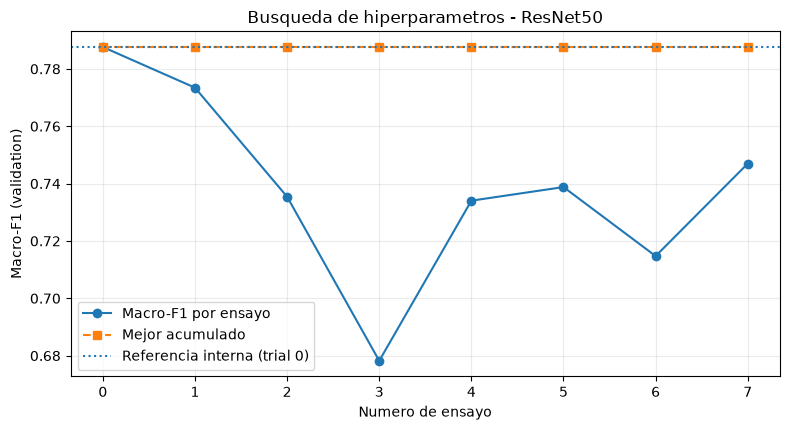

Artefactos principales guardados en: 7. resultados/optimizacion_hiperparametros
La seleccion final permanece provisional hasta comprobar su estabilidad.


In [9]:
filas = []
for ensayo in estudio.get_trials(deepcopy=False):
    if ensayo.state.name == "WAITING":
        continue
    fila = {
        "trial": ensayo.number,
        "estado": ensayo.state.name,
        "learning_rate": ensayo.params.get("learning_rate", np.nan),
        "dropout": ensayo.params.get("dropout", np.nan),
        "macro_f1": ensayo.value if ensayo.value is not None else np.nan,
    }
    for campo in ("accuracy", "recall_russet", "precision_russet", "epocas",
                  "mejor_epoca_val_loss", "segundos", "carpeta"):
        fila[campo] = ensayo.user_attrs.get(campo, np.nan)
    filas.append(fila)

if not filas:
    print("Aun no hay ensayos terminados. No se generan resultados ficticios.")
else:
    resultados = pd.DataFrame(filas).sort_values("trial").reset_index(drop=True)
    resultados.to_csv(SALIDA_HPO / "hpo_runs.csv", index=False)
    completos = resultados.loc[(resultados["estado"] == "COMPLETE") & resultados["macro_f1"].notna()].copy()
    if completos.empty:
        print("No hay ensayos COMPLETED con Macro-F1 valido.")
    else:
        ranking = completos.sort_values(["macro_f1", "recall_russet"], ascending=False)
        ranking.to_csv(SALIDA_HPO / "comparacion_configuraciones.csv", index=False)
        print("Mejores configuraciones observadas en VALIDATION (top-5):")
        display(ranking[["trial", "learning_rate", "dropout", "macro_f1", "accuracy",
                         "recall_russet", "precision_russet", "epocas", "segundos"]].head(5).round(5))

        mejor = ranking.iloc[0]
        referencia_interna = completos.loc[completos["trial"] == 0]
        ref_val = float(referencia_interna.iloc[0]["macro_f1"]) if len(referencia_interna) else np.nan
        historica = float(metricas_historicas["macro_f1"])
        delta = float(mejor["macro_f1"] - ref_val) if np.isfinite(ref_val) else np.nan

        fig, ax = plt.subplots(figsize=(8, 4.4))
        ax.plot(completos["trial"], completos["macro_f1"], "o-", label="Macro-F1 por ensayo")
        ax.plot(completos["trial"], completos["macro_f1"].cummax(), "s--", label="Mejor acumulado")
        if np.isfinite(ref_val):
            ax.axhline(ref_val, linestyle=":", label="Referencia interna (trial 0)")
        ax.set_xlabel("Numero de ensayo")
        ax.set_ylabel("Macro-F1 (validation)")
        ax.set_title("Busqueda de hiperparametros - ResNet50")
        ax.legend()
        ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(SALIDA_HPO / "evolucion_busqueda.png", dpi=160)
        plt.show()
        plt.close(fig)

        resumen = [
            "# Resultados de optimización de hiperparámetros",
            "",
            "Modelo: ResNet50 ImageNet con ajuste fino del bloque conv5, cabeza D1 y fotometria train.",
            "Metrica central: Macro-F1 sobre VALIDATION. TEST no utilizado.",
            f"Metodo: Optuna RandomSampler, semilla {SEMILLA}; {len(completos)} ensayos completados de {N_TRIALS_OBJETIVO} previstos.",
            f"Rango de learning rate (log): {LR_RANGO[0]:g} a {LR_RANGO[1]:g}.",
            f"Rango de dropout: {DROPOUT_RANGO[0]:.2f} a {DROPOUT_RANGO[1]:.2f}.",
            f"Presupuesto de entrenamiento: hasta {EPOCAS_MAXIMAS} epocas, lote {LOTE}, early stopping por val_loss.",
            "",
            f"Mejor ensayo: {int(mejor['trial'])}.",
            f"Learning rate: {float(mejor['learning_rate']):.8g}; dropout: {float(mejor['dropout']):.4f}.",
            f"Macro-F1 de validation: {float(mejor['macro_f1']):.4f}.",
            f"Recall RUSSET: {float(mejor['recall_russet']):.4f}.",
            f"Macro-F1 historico FT_D1_PHOTO: {historica:.4f} (solo antecedente; no sustituye la referencia interna).",
            f"Macro-F1 referencia interna, trial 0: {ref_val:.4f}" if np.isfinite(ref_val) else "Referencia interna aun no terminada.",
            f"Diferencia frente al trial 0: {delta:+.4f}" if np.isfinite(delta) else "Diferencia frente al trial 0 no disponible.",
            "",
            "Decision: configuracion candidata preliminar; no se adopta automaticamente por una mejora puntual en validation.",
            "Verificar estabilidad con repeticiones independientes, tradeoffs por clase y costo antes de adoptarla.",
            "No se calcularon media ni desviacion estandar entre semillas: una corrida por configuracion.",
            "Un ajuste de hiperparametros en esta misma particion puede optimizarse al ruido de validation.",
            "Estos ensayos no incluyen una nueva evaluacion independiente sobre TEST ni resultados de despliegue industrial.",
        ]
        (SALIDA_HPO / "resumen_decision.md").write_text("\n".join(resumen) + "\n", encoding="utf-8")
        print("Artefactos principales guardados en:", SALIDA_HPO.relative_to(RAIZ))
        print("La seleccion final permanece provisional hasta comprobar su estabilidad.")
